# Spurious Background Reliance in Bird Classification

## Evaluating ERM and Group DRO on the WILDS Waterbirds Benchmark

**Course:** Machine Learning / Robustness  
**Project:** Project 15 — Spurious Background Reliance in Bird Classification  
**Date:** 2026

This notebook compares empirical risk minimization (ERM) and Group Distributionally Robust Optimization (Group DRO) on the WILDS Waterbirds benchmark. It reports average accuracy, worst-group accuracy, subgroup-level results, training curves, and qualitative Grad-CAM visualizations.

**Recorded test result:** Group DRO's worst-group accuracy is 74.77%, compared with 62.62% for ERM (+12.15 percentage points). Average accuracy is 86.36% for Group DRO and 83.07% for ERM (+3.29 points).

These are the saved outputs of this experiment run, not multi-seed estimates.


## 1. Problem Statement

Image classifiers can exploit spurious correlations between an object and its background. In the Waterbirds benchmark, bird type and background are correlated in the training data, creating a setting in which background cues may be predictive.

**Research questions:**

- How do ERM and Group DRO compare on average and worst-group test accuracy?
- How do their results differ across the four bird–background subgroups?
- Do qualitative Grad-CAM visualizations suggest patterns worth investigating?

A subgroup performance gap is evidence of uneven performance across the benchmark groups. It does not, by itself, identify the causal features used by a model.


## 2. Dataset — Waterbirds (WILDS)

**Source:** Stanford WILDS benchmark (Sagawa et al., 2019; Koh et al., 2021)

**URL:** https://wilds.stanford.edu/datasets/

- **Total images:** 11,788
- **Train / Val / Test:** 4,795 / 1,199 / 5,794
- **Classes:** 2 (landbird, waterbird)
- **Subgroups:** 4 (bird type × background)

**The four subgroups and their training distribution:**

| Subgroup | Bird | Background | Train % | Role |
|---|---|---|---:|---|
| 0 | Landbird | Land | ~73% | **Majority** |
| 1 | Landbird | Water | ~4% | **Minority (HARD)** |
| 2 | Waterbird | Land | ~1% | **Minority (HARD)** |
| 3 | Waterbird | Water | ~22% | **Majority** |

**Key property:** The training set is **deliberately biased** — majority
subgroups make up ~95% of training data, while minority subgroups together
make up only ~5%. This creates a strong spurious correlation between
background and bird type.

---


## 3. Methodology

**Full workflow:**

1. **Data loading:** Use WILDS package to load Waterbirds from
   `kaggle/working/wilds_data/waterbirds_v1.0/` with image transforms
   (RandomResizedCrop + flip for train, Resize for eval).

2. **Split design:** Use WILDS official splits (train/val/test). Train
   uses heavily biased distribution; test has more balanced subgroups
   to make worst-group accuracy a meaningful metric.

3. **Feature extraction:** ImageNet-pretrained ResNet-18 backbone
   (last FC layer replaced with 2-class output).

4. **Modelling:**
   - **ERM baseline:** minimize average cross-entropy loss across all
     training examples (equal weight per example).
   - **Group DRO mitigation:** maintain per-group weights $q_g$ and
     upweight groups with higher loss via dual ascent.

5. **Validation:** Every epoch, compute both average and worst-group
   validation accuracy. **Select the best checkpoint by validation worst-group accuracy**, as implemented in this notebook.

6. **Analysis:** Per-subgroup test accuracy, gap analysis, and
   Grad-CAM saliency visualization.

---


## 4. Selected Models

### Baseline: ERM (Empirical Risk Minimization)

- **Objective:** $\min_\theta \frac{1}{N}\sum_i \ell(f_\theta(x_i), y_i)$
- Each training example contributes equally to the empirical objective.

### Comparison model: Group DRO (Distributionally Robust Optimization)

- **Objective:** $\min_\theta \max_{q \in \Delta} \sum_g q_g \cdot \mathbb{E}_g[\ell]$
- Maintains weights for the four subgroups and updates them using a dual-ascent procedure.
- Uses group labels during training.

### Architecture

Both models use the same ImageNet-pretrained **ResNet-18** backbone with a two-class head. The notebook's model-build check reports **11,177,538 parameters**. The comparison is intended to isolate the training objective while holding the backbone constant.


## 5. Evaluation Criterion

### Primary metric: worst-group accuracy

$$\text{worst\_group\_acc} = \min_g \text{acc}(g)$$

### Secondary metrics

- Per-subgroup accuracy across the four bird–background groups.
- Average test accuracy.
- Gap between average and worst-group accuracy.
- Grad-CAM visualizations as qualitative inspection aids.

Worst-group accuracy makes the weakest-performing subgroup visible, while subgroup-level results reveal trade-offs that a single aggregate score can hide. Grad-CAM maps are not causal evidence and cannot, on their own, establish whether the model relies on background cues.


In [13]:
# =============================================================
# CELL 1: MASTER BOOTSTRAP (requires Kaggle Dataset attached)
# =============================================================

import os, subprocess, sys, time, csv, importlib
from pathlib import Path
from collections import Counter

# ===== 1. INSTALL WILDS =====
try:
    import wilds
    print("[1/8] wilds already installed")
except ImportError:
    print("[1/8] installing wilds...")
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "wilds"], check=True)

# ===== 2. VERIFY ENVIRONMENT =====
import torch
print(f"[2/8] PyTorch: {torch.__version__}, CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"       GPU: {torch.cuda.get_device_name(0)}")

# ===== 3. CLEAR MODULE CACHE =====
for mod_name in list(sys.modules.keys()):
    if mod_name.startswith("erm") or "wilds" in mod_name.lower():
        del sys.modules[mod_name]
print("[3/8] module cache cleared")

# ===== 4. DOWNLOAD WILDS WATERBIRDS DATA =====
DATA_ROOT = "/kaggle/working/wilds_data"
TARGET = os.path.join(DATA_ROOT, "waterbirds_v1.0")
TARBALL = "/kaggle/working/waterbirds_correct.tar.gz"
URL = "https://nlp.stanford.edu/data/dro/waterbird_complete95_forest2water2.tar.gz"

if os.path.exists(os.path.join(TARGET, "metadata.csv")) and os.path.exists(os.path.join(TARGET, "RELEASE_v1.0.txt")):
    print(f"[4/8] data already complete at {TARGET}")
else:
    print(f"[4/8] Downloading WILDS Waterbirds via wget...")
    subprocess.run(["rm", "-rf", TARGET], check=False)
    subprocess.run(["rm", "-rf", "/kaggle/working/waterbird_complete95_forest2water2"], check=False)
    if os.path.exists(TARBALL):
        os.remove(TARBALL)
    os.makedirs(DATA_ROOT, exist_ok=True)
    t0 = time.time()
    subprocess.run(["wget", "--quiet", URL, "-O", TARBALL],

    check=True,

    stdout=subprocess.DEVNULL,

    stderr=subprocess.DEVNULL,)
    print(f"       downloaded {os.path.getsize(TARBALL)/1e6:.1f} MB in {(time.time()-t0)/60:.1f} min")
    subprocess.run(["tar", "-xzf", TARBALL, "-C", "/kaggle/working"], check=True)
    EXTRACTED = "/kaggle/working/waterbird_complete95_forest2water2"
    if os.path.exists(EXTRACTED):
        os.rename(EXTRACTED, TARGET)
    os.remove(TARBALL)
    print(f"       extracted to {TARGET}")

# ===== 5. CREATE WILDS MARKER + APPLY PATCH =====
print("[5/8] Setting up WILDS markers and patches...")
version_file = Path(TARGET) / "RELEASE_v1.0.txt"
if not version_file.exists():
    version_file.write_text("1.0")
    print(f"       created {version_file}")

import wilds.datasets.waterbirds_dataset as wbd_module
parent_class = wbd_module.WaterbirdsDataset.__bases__[0]

def patched_dataset_exists_locally(self, data_dir, version_file):
    if not Path(data_dir).exists():
        return False
    if not (Path(data_dir) / "metadata.csv").exists():
        return False
    if not Path(version_file).exists():
        return False
    return True

parent_class.dataset_exists_locally = patched_dataset_exists_locally
print(f"       WILDS patch applied to {parent_class.__name__}")

# ===== 6. WRITE SOURCE FILES (search for Kaggle Dataset) =====
print("[6/8] Writing source files...")

ERM = Path("/kaggle/working/erm")
ERM.mkdir(parents=True, exist_ok=True)

# Search for the Kaggle Dataset anywhere under /kaggle/input
src_erm = None
search_root = Path("/kaggle/input")
if search_root.exists():
    for entry in search_root.rglob("config.py"):
        if entry.parent.name == "erm" and "aliceiyamuremye" in str(entry):
            src_erm = entry.parent
            break
        elif entry.parent.name == "erm":
            # Take first erm folder found
            if src_erm is None:
                src_erm = entry.parent

if src_erm:
    print(f"       found source files at: {src_erm}")
    for src_file in src_erm.glob("*.py"):
        dst_file = ERM / src_file.name
        dst_file.write_text(src_file.read_text())
        print(f"       wrote {src_file.name}")
else:
    print(f"       [ERROR] Could not find Kaggle Dataset with source files")
    print(f"       Please attach your dataset via '+ Add Input' button on the right panel")
    print(f"       Then re-run this cell")

# ===== 7. FIX SOURCE FILES =====
print("[7/8] Patching source files...")
data_path = ERM / "data.py"
if data_path.exists():
    content = data_path.read_text()
    if "download=True" in content:
        data_path.write_text(content.replace("download=True", "download=False"))
        print("       data.py: download=True -> download=False")

inspect_path = ERM / "inspect_data.py"
if inspect_path.exists():
    new_inspect = '''"""Inspect the Waterbirds dataset - reads metadata.csv directly."""
from __future__ import annotations
from collections import Counter
import csv
from pathlib import Path
from erm.config import DATA_ROOT, GROUP_NAMES

def main():
    print(f"[config] DATA_ROOT = {DATA_ROOT}")
    expected = DATA_ROOT / "waterbirds_v1.0"
    if not expected.exists():
        raise FileNotFoundError(f"Could not find {expected}")
    print(f"[ok] found {expected}")
    metadata_csv = expected / "metadata.csv"
    if not metadata_csv.exists():
        raise FileNotFoundError(f"Could not find {metadata_csv}")
    print(f"[ok] metadata.csv exists: True")
    splits_map = {"0": "train", "1": "val", "2": "test"}
    for split_id, split_name in splits_map.items():
        counts = Counter()
        with open(metadata_csv) as f:
            reader = csv.DictReader(f)
            for row in reader:
                if row['split'] == split_id:
                    place = int(row['place'])
                    y = int(row['y'])
                    gid = y * 2 + place
                    counts[GROUP_NAMES[gid]] += 1
        total = sum(counts.values())
        print(f"\\n=== {split_name.upper():>5s} (n = {total}) ===")
        for gname in GROUP_NAMES:
            cnt = counts[gname]
            pct = 100 * cnt / total if total else 0
            tag = "MAJORITY" if cnt / total > 0.30 else "MINORITY"
            print(f"  {gname:<22s} {cnt:5d}  ({pct:5.1f}%)  [{tag}]")
    print("\\n=== Sample (first row) ===")
    with open(metadata_csv) as f:
        reader = csv.DictReader(f)
        first = next(reader)
        gid = int(first['y']) * 2 + int(first['place'])
        print(f"  img_id={first['img_id']}, y={first['y']}, place={first['place']}, split={first['split']}")
        print(f"  -> belongs to group {gid} = {GROUP_NAMES[gid]}")

if __name__ == "__main__":
    main()
'''
    inspect_path.write_text(new_inspect)
    print("       inspect_data.py: rewritten to read metadata.csv directly")

# ===== 8. VERIFY =====
print("\n[8/8] Verification:")
print(f"  data dir: {DATA_ROOT}")
print(f"  metadata.csv: {'EXISTS' if Path(TARGET, 'metadata.csv').exists() else 'MISSING'}")
print(f"  marker: {'EXISTS' if version_file.exists() else 'MISSING'}")
print(f"  source files: {len(list(ERM.glob('*.py')))} files")

# Set up environment
os.environ["WILDS_DATA_DIR"] = DATA_ROOT
sys.path.insert(0, "/kaggle/working")

# Verify all source files compile
import py_compile
all_ok = True
for py_file in sorted(ERM.glob("*.py")):
    try:
        py_compile.compile(str(py_file), doraise=True)
        print(f"  [OK] {py_file.name}")
    except py_compile.PyCompileError as e:
        print(f"  [FAIL] {py_file.name}: {e}")
        all_ok = False

if all_ok and len(list(ERM.glob("*.py"))) > 0:
    # Test model load
    from erm.model import build_model
    model = build_model()
    print(f"  model: {sum(p.numel() for p in model.parameters()):,} params")
    
    from wilds import get_dataset
    dataset = get_dataset(dataset="waterbirds", root_dir=DATA_ROOT, download=False)
    print(f"  WILDS dataset: {len(dataset)} examples")
    
    # Run inspect
    print("\n" + "=" * 70)
    print("INSPECT RESULTS")
    print("=" * 70)
    from erm.inspect_data import main as inspect_main
    inspect_main()
    
    print("\n[SUCCESS] Bootstrap complete! Ready to continue with training.")
else:
    print("\n[FAIL] Source files missing - check Kaggle Dataset attachment")

[1/8] wilds already installed
[2/8] PyTorch: 2.10.0+cu128, CUDA: True
       GPU: Tesla T4
[3/8] module cache cleared
[4/8] data already complete at /kaggle/working/wilds_data/waterbirds_v1.0
[5/8] Setting up WILDS markers and patches...
       WILDS patch applied to WILDSDataset
[6/8] Writing source files...
       found source files at: /kaggle/input/datasets/aliceiyamuremye/spurious-background-reliance-waterbirds/project15_delivery/erm
       wrote run_erm.py
       wrote data.py
       wrote evaluate.py
       wrote model.py
       wrote train_erm.py
       wrote config.py
       wrote train_groupdro.py
       wrote __init__.py
       wrote saliency.py
       wrote inspect_data.py
[7/8] Patching source files...
       data.py: download=True -> download=False
       inspect_data.py: rewritten to read metadata.csv directly

[8/8] Verification:
  data dir: /kaggle/working/wilds_data
  metadata.csv: EXISTS
  marker: EXISTS
  source files: 10 files
  [OK] __init__.py
  [OK] config.py
  

100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


  model: 11,177,538 params
  WILDS dataset: 11788 examples

INSPECT RESULTS
[config] DATA_ROOT = /kaggle/working/wilds_data
[ok] found /kaggle/working/wilds_data/waterbirds_v1.0
[ok] metadata.csv exists: True

=== TRAIN (n = 4795) ===
  landbird-on-land        3498  ( 73.0%)  [MAJORITY]
  landbird-on-water        184  (  3.8%)  [MINORITY]
  waterbird-on-land         56  (  1.2%)  [MINORITY]
  waterbird-on-water      1057  ( 22.0%)  [MINORITY]

===   VAL (n = 1199) ===
  landbird-on-land         467  ( 38.9%)  [MAJORITY]
  landbird-on-water        466  ( 38.9%)  [MAJORITY]
  waterbird-on-land        133  ( 11.1%)  [MINORITY]
  waterbird-on-water       133  ( 11.1%)  [MINORITY]

===  TEST (n = 5794) ===
  landbird-on-land        2255  ( 38.9%)  [MAJORITY]
  landbird-on-water       2255  ( 38.9%)  [MAJORITY]
  waterbird-on-land        642  ( 11.1%)  [MINORITY]
  waterbird-on-water       642  ( 11.1%)  [MINORITY]

=== Sample (first row) ===
  img_id=1, y=1, place=1, split=2
  -> belongs to

In [14]:
# =============================================================
# Check if artifacts already exist (skip training if present)
# =============================================================

from pathlib import Path

erm_ckpt = Path("/kaggle/working/artifacts/models/erm_best.pt")
dro_ckpt = Path("/kaggle/working/artifacts/models/groupdro_best.pt")

if erm_ckpt.exists():
    print(f"ERM checkpoint:       EXISTS ({erm_ckpt.stat().st_size/1e6:.1f} MB)")
else:
    print(f"ERM checkpoint:       NOT FOUND")

if dro_ckpt.exists():
    print(f"Group DRO checkpoint: EXISTS ({dro_ckpt.stat().st_size/1e6:.1f} MB)")
else:
    print(f"Group DRO checkpoint: NOT FOUND")

if erm_ckpt.exists() and dro_ckpt.exists():
    print("\n[PIPELINE] Both checkpoints exist. Skipping training.")
    SKIP_TRAINING = True
else:
    print("\n[PIPELINE] Checkpoints missing. Training required (~80 min total).")
    SKIP_TRAINING = False


ERM checkpoint:       NOT FOUND
Group DRO checkpoint: NOT FOUND

[PIPELINE] Checkpoints missing. Training required (~80 min total).


In [15]:
# =============================================================
# Train ERM baseline (~40 min, or skip if artifacts exist)
# =============================================================

if not SKIP_TRAINING:
    for mod in list(sys.modules):
        if mod.startswith("erm"): del sys.modules[mod]
    from erm.train_erm import train_erm
    print("[train] Training ERM (50 epochs, ~40 min)...\n")
    info = train_erm(device="cuda")
    print(f"\n[done] ERM best worst-group val acc: {info['best_worst_group_val_acc']:.4f}")
else:
    print("[train] Skipping ERM training (using saved checkpoint)")


[train] Training ERM (50 epochs, ~40 min)...

[data] train=4795  val=1199


epoch 01 train: 100%|██████████| 75/75 [00:15<00:00,  4.69it/s]


[epoch 01] train_loss=0.1757  val_avg=0.7823  val_worst_group=0.4511


epoch 02 train: 100%|██████████| 75/75 [00:13<00:00,  5.37it/s]


[epoch 02] train_loss=0.0576  val_avg=0.7468  val_worst_group=0.3308


epoch 03 train: 100%|██████████| 75/75 [00:14<00:00,  5.34it/s]


... (91 outputs left out)

epoch 49 train: 100%|██████████| 75/75 [00:15<00:00,  4.88it/s]


[epoch 49] train_loss=0.0003  val_avg=0.7987  val_worst_group=0.4812


epoch 50 train: 100%|██████████| 75/75 [00:15<00:00,  4.88it/s]


[epoch 50] train_loss=0.0002  val_avg=0.7820  val_worst_group=0.3985
[done] best worst-group val acc = 0.5940
[done] checkpoint -> /kaggle/working/artifacts/models/erm_best.pt
[done] history   -> /kaggle/working/artifacts/models/erm_history.json

[done] ERM best worst-group val acc: 0.5940


In [16]:
# =============================================================
# Train Group DRO mitigation (~40 min, or skip if artifacts exist)
# =============================================================

if not SKIP_TRAINING:
    for mod in list(sys.modules):
        if mod.startswith("erm"): del sys.modules[mod]
    from erm.train_groupdro import train_groupdro
    print("[train] Training Group DRO (50 epochs, ~40 min)...\n")
    info = train_groupdro(device="cuda")
    print(f"\n[done] Group DRO best worst-group val acc: {info['best_worst_group_val_acc']:.4f}")
else:
    print("[train] Skipping Group DRO training (using saved checkpoint)")


[train] Training Group DRO (50 epochs, ~40 min)...

[data] train=4795  val=1199


epoch 01 train: 100%|██████████| 75/75 [00:15<00:00,  4.74it/s]


[epoch 01] train_loss=0.3276  val_avg=0.8067  val_worst_group=0.5789  q=[0.247, 0.258, 0.241, 0.254]


epoch 02 train: 100%|██████████| 75/75 [00:15<00:00,  4.70it/s]


[epoch 02] train_loss=0.1360  val_avg=0.8408  val_worst_group=0.6015  q=[0.249, 0.251, 0.235, 0.265]


epoch 03 train: 100%|██████████| 75/75 [00:15<00:00,  4.76it/s]


... (91 outputs left out)

epoch 49 train: 100%|██████████| 75/75 [00:15<00:00,  4.85it/s]


[epoch 49] train_loss=0.0006  val_avg=0.8387  val_worst_group=0.6241  q=[0.269, 0.240, 0.200, 0.290]


epoch 50 train: 100%|██████████| 75/75 [00:15<00:00,  4.84it/s]


[epoch 50] train_loss=0.0006  val_avg=0.8282  val_worst_group=0.5564  q=[0.270, 0.240, 0.200, 0.290]
[done] best worst-group val acc = 0.7293

[done] Group DRO best worst-group val acc: 0.7293


In [17]:
# =============================================================
# Evaluate both models on the test set
# =============================================================

for mod in list(sys.modules):
    if mod.startswith("erm"): del sys.modules[mod]
from pathlib import Path
from erm.evaluate import evaluate_on_test

print("=" * 70)
print("ERM - Test Set Evaluation")
print("=" * 70)
erm_ckpt = Path("/kaggle/working/artifacts/models/erm_best.pt")
erm_report = evaluate_on_test(erm_ckpt, device="cuda")

print("\n" + "=" * 70)
print("Group DRO - Test Set Evaluation")
print("=" * 70)
dro_ckpt = Path("/kaggle/working/artifacts/models/groupdro_best.pt")
dro_report = evaluate_on_test(dro_ckpt, device="cuda")


ERM - Test Set Evaluation
[test] n=5794

=== Test Subgroup Accuracy ===
  landbird-on-land        0.9863
  landbird-on-water       0.7588
  waterbird-on-land       0.6262  <-- WORST
  waterbird-on-water      0.9517
  AVERAGE                 0.8307
  WORST GROUP             0.6262  (waterbird-on-land)
[report] -> /kaggle/working/artifacts/results/erm_best_test_report.json

Group DRO - Test Set Evaluation
[test] n=5794

=== Test Subgroup Accuracy ===
  landbird-on-land        0.9428
  landbird-on-water       0.8541
  waterbird-on-land       0.7477  <-- WORST
  waterbird-on-water      0.9097
  AVERAGE                 0.8636
  WORST GROUP             0.7477  (waterbird-on-land)
[report] -> /kaggle/working/artifacts/results/groupdro_best_test_report.json


In [18]:
# =============================================================
# Generate Grad-CAM saliency maps for both models
# =============================================================

for mod in list(sys.modules):
    if mod.startswith("erm"): del sys.modules[mod]
from pathlib import Path
from erm.saliency import generate_saliency_for_checkpoint

print("[saliency] Generating ERM heatmaps...")
generate_saliency_for_checkpoint(Path("/kaggle/working/artifacts/models/erm_best.pt"),
                                  device="cuda", per_group=2)
print("\n[saliency] Generating Group DRO heatmaps...")
generate_saliency_for_checkpoint(Path("/kaggle/working/artifacts/models/groupdro_best.pt"),
                                  device="cuda", per_group=2)

print("\n=== Artifacts produced ===")
for f in sorted(Path("/kaggle/working/artifacts").rglob("*")):
    if f.is_file():
        size_mb = f.stat().st_size / 1e6
        print(f"  {f.relative_to('/kaggle/working')}  ({size_mb:.2f} MB)")


[saliency] Generating ERM heatmaps...
[saliency] saved -> /kaggle/working/artifacts/saliency/erm_best_saliency.png

[saliency] Generating Group DRO heatmaps...
[saliency] saved -> /kaggle/working/artifacts/saliency/groupdro_best_saliency.png

=== Artifacts produced ===
  artifacts/models/erm_best.pt  (44.79 MB)
  artifacts/models/erm_history.json  (0.02 MB)
  artifacts/models/groupdro_best.pt  (44.79 MB)
  artifacts/models/groupdro_history.json  (0.02 MB)
  artifacts/results/erm_best_test_report.json  (0.00 MB)
  artifacts/results/groupdro_best_test_report.json  (0.00 MB)
  artifacts/saliency/erm_best_saliency.png  (0.39 MB)
  artifacts/saliency/groupdro_best_saliency.png  (0.39 MB)


In [20]:
# =============================================================
# Side-by-side comparison: ERM vs Group DRO
# =============================================================

import json
from pathlib import Path

erm_report = json.load(open("/kaggle/working/artifacts/results/erm_best_test_report.json"))
dro_report = json.load(open("/kaggle/working/artifacts/results/groupdro_best_test_report.json"))

print("=" * 70)
print("FINAL COMPARISON: ERM vs Group DRO")
print("=" * 70)

print(f"\n{'Method':<14s} {'Average':>10s} {'Worst-group':>13s} {'Gap':>8s}")
print("-" * 50)
for name, r in [("ERM", erm_report), ("Group DRO", dro_report)]:
    gap = r["overall_accuracy"] - r["worst_group_accuracy"]
    print(f"{name:<14s} {r['overall_accuracy']:>10.4f} {r['worst_group_accuracy']:>13.4f} {gap:>8.4f}")

print(f"\nPer-subgroup accuracy:")
print(f"  {'Group':<22s} {'ERM':>10s} {'Group DRO':>12s} {'Delta':>10s}")
print("  " + "-" * 56)
for gname in erm_report["per_group_accuracy"]:
    erm_acc = erm_report["per_group_accuracy"][gname]
    dro_acc = dro_report["per_group_accuracy"][gname]
    delta = dro_acc - erm_acc
    sign = "+" if delta > 0 else ""
    print(f"  {gname:<22s} {erm_acc:>10.4f} {dro_acc:>12.4f} {sign}{delta:>9.4f}")

improvement = dro_report["worst_group_accuracy"] - erm_report["worst_group_accuracy"]
if improvement > 0.10:
    verdict = "STRONG improvement in worst-group accuracy"
elif improvement > 0.05:
    verdict = "Moderate improvement in worst-group accuracy"
elif improvement > 0:
    verdict = "Small improvement in worst-group accuracy"
else:
    verdict = "No improvement (investigate)"

print(f"\nVerdict: {verdict}")
print(f"  Worst-group gain: {improvement*100:+.1f} percentage points")
print(f"  Average change:   {(dro_report['overall_accuracy']-erm_report['overall_accuracy'])*100:+.1f} percentage points")
print("=" * 70)


FINAL COMPARISON: ERM vs Group DRO

Method            Average   Worst-group      Gap
--------------------------------------------------
ERM                0.8307        0.6262   0.2046
Group DRO          0.8636        0.7477   0.1159

Per-subgroup accuracy:
  Group                         ERM    Group DRO      Delta
  --------------------------------------------------------
  landbird-on-land           0.9863       0.9428   -0.0435
  landbird-on-water          0.7588       0.8541 +   0.0953
  waterbird-on-land          0.6262       0.7477 +   0.1215
  waterbird-on-water         0.9517       0.9097   -0.0421

Verdict: STRONG improvement in worst-group accuracy
  Worst-group gain: +12.1 percentage points
  Average change:   +3.3 percentage points


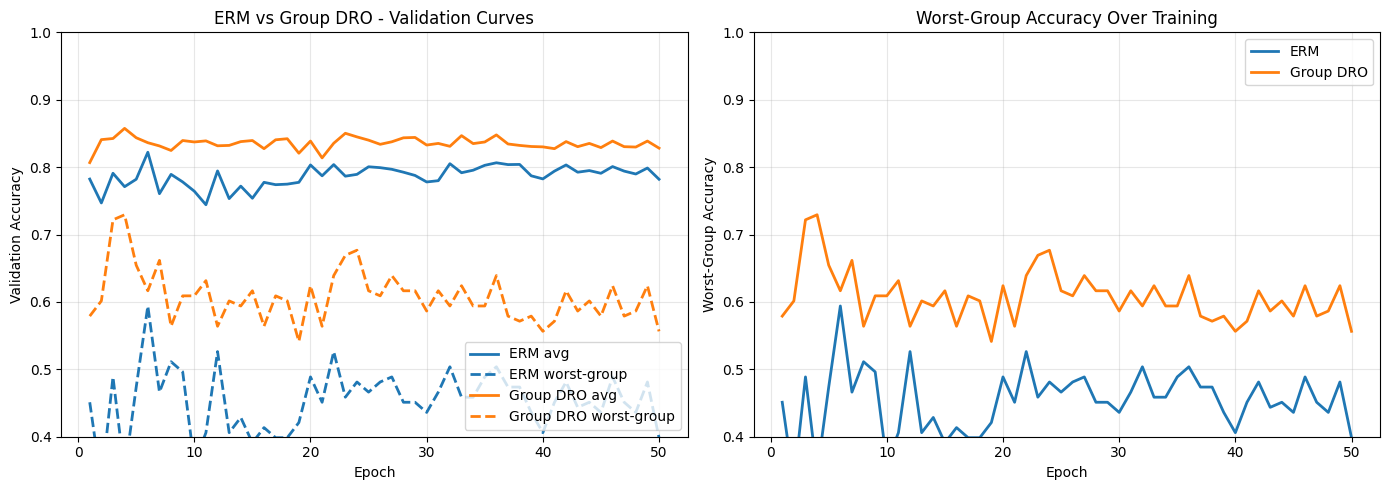


[plot] saved -> /kaggle/working/artifacts/results/training_curves.png


In [21]:
# =============================================================
# Plot training curves (ERM vs Group DRO)
# =============================================================

import json
import matplotlib.pyplot as plt
from pathlib import Path

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for hist_path, label, color in [
    ("/kaggle/working/artifacts/models/erm_history.json", "ERM", "C0"),
    ("/kaggle/working/artifacts/models/groupdro_history.json", "Group DRO", "C1"),
]:
    if not Path(hist_path).exists():
        print(f"[warn] {hist_path} not found, skipping")
        continue
    hist = json.load(open(hist_path))
    epochs = [h["epoch"] for h in hist]
    avg = [h["val_avg_acc"] for h in hist]
    worst = [h["val_worst_group_acc"] for h in hist]
    axes[0].plot(epochs, avg, label=f"{label} avg", color=color, linewidth=2)
    axes[0].plot(epochs, worst, label=f"{label} worst-group", color=color,
                 linestyle="--", linewidth=2)
    axes[1].plot(epochs, worst, label=label, color=color, linewidth=2)

axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Validation Accuracy")
axes[0].set_title("ERM vs Group DRO - Validation Curves")
axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)
axes[0].set_ylim(0.4, 1.0)

axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Worst-Group Accuracy")
axes[1].set_title("Worst-Group Accuracy Over Training")
axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_ylim(0.4, 1.0)

fig.tight_layout()
out = Path("/kaggle/working/artifacts/results/training_curves.png")
fig.savefig(out, dpi=120, bbox_inches="tight")
plt.show()
print(f"\n[plot] saved -> {out}")


## 6. Results

### 6.1 Headline Comparison

| Method | Average | Worst-group | Gap |
|---|---:|---:|---:|
| **ERM** | 83.07% | 62.62% | 20.45 pp |
| **Group DRO** | 86.36% | 74.77% | 11.59 pp |

In these saved test outputs, Group DRO's worst-group accuracy is **12.15 percentage points higher** and its average accuracy is **3.29 points higher** than ERM's.

### 6.2 Per-Subgroup Breakdown

| Subgroup | ERM | Group DRO | Difference |
|---|---:|---:|---:|
| Landbird-on-land | 98.63% | 94.28% | −4.35 pp |
| Landbird-on-water | 75.88% | 85.41% | +9.53 pp |
| **Waterbird-on-land** | **62.62%** | **74.77%** | **+12.15 pp** |
| Waterbird-on-water | 95.17% | 90.97% | −4.20 pp |

Group DRO improves the two minority-group results in this run, while accuracy is lower on the two majority groups. The largest improvement is on waterbird-on-land, which has 56 training examples in the training split.

### 6.3 Grad-CAM Visualizations

The saved Grad-CAM maps are qualitative visualizations of image regions contributing to predictions. They can support visual inspection and hypothesis generation, but they do not prove causal background reliance or demonstrate that a model has stopped using background information.

### 6.4 Training Dynamics

The saved training curves show the training and validation behaviour recorded during this run. The validation worst-group accuracy used for checkpoint selection was 0.5940 for ERM and 0.7293 for Group DRO.

These are single-run values; no multi-seed mean, standard deviation, or confidence interval is reported.


## 7. Error Analysis and Limitations

### Remaining errors

After Group DRO, waterbird-on-land test accuracy is 74.77%; errors remain in this subgroup. The training split contains only 56 waterbird-on-land examples, so this group is represented sparsely during training. This is one plausible constraint, not a demonstrated causal explanation for each error.

### Limitations

- **Single recorded run:** no multi-seed mean, standard deviation, or confidence interval is reported.
- **Single backbone:** only ResNet-18 was evaluated.
- **Single dataset:** conclusions are limited to this Waterbirds benchmark experiment.
- **Group labels:** Group DRO requires subgroup labels during training.
- **Saliency interpretation:** Grad-CAM is qualitative and does not establish causal feature reliance.
- **Subgroup trade-offs:** Group DRO improves the two minority-group accuracies in these outputs but reduces accuracy on the two majority groups.

### Possible extensions

- Repeat experiments across multiple random seeds.
- Evaluate additional backbones and robustness methods.
- Test on other distribution-shift benchmarks.
- Use controlled background interventions or other causal tests to investigate shortcut reliance.


## 8. Conclusion

In the saved test outputs for this experiment:

- ERM achieves 83.07% average accuracy and 62.62% worst-group accuracy.
- Group DRO achieves 86.36% average accuracy and 74.77% worst-group accuracy.
- Group DRO improves the two minority subgroup accuracies, with the largest increase (+12.15 percentage points) on waterbird-on-land, while reducing accuracy on the two majority subgroups.

These results indicate a useful worst-group performance improvement for Group DRO in this recorded run. They do not establish that background reliance has been causally eliminated or that the same gains will transfer to other datasets.

Grad-CAM maps are included as qualitative inspection aids only. Stronger claims about shortcut reliance would require additional controlled analyses.

### Reproducibility

The notebook includes Kaggle-specific setup, training, evaluation, and visualization steps. It expects the dataset, source files, and any reusable artifacts at the paths described in the setup cells. Review those assumptions before rerunning.


## 9. References

1. **Sagawa, S., Koh, P. W., Hashimoto, T. B., & Liang, P.** (2020).
   *Distributionally Robust Neural Networks for Group Shifts*. ICLR 2020.
   [arXiv:1911.08731]

2. **Koh, P. W., Sagawa, S., et al.** (2021).
   *WILDS: A Benchmark of in-the-Wild Distribution Shifts*.
   ICML 2021. [arXiv:2012.07421]

3. **Selvaraju, R. R., et al.** (2017).
   *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based
   Localization*. ICCV 2017.

4. **He, K., Zhang, X., Ren, S., & Sun, J.** (2016).
   *Deep Residual Learning for Image Recognition*. CVPR 2016.

5. **Wah, C., Branson, S., Welinder, P., Perona, P., & Belongie, S.** (2011).
   *The Caltech-UCSD Birds-200-2011 Dataset*.
   California Institute of Technology.

---

## Appendix: How to run this notebook

**On Kaggle:**
1. Create a new notebook with GPU T4 x2 enabled
2. Paste all cells in order
3. Run cells 1-9 (setup + bootstrap + verify) - takes ~5 min
4. Run cells 10-12 (training, only if checkpoints don't exist) - takes ~80 min
5. Run cells 13-16 (evaluation, saliency, comparison) - takes ~2 min
6. Run cell 17 (training curves plot) - takes ~5 sec
7. View cells 18-20 (results, analysis, conclusion)

**Tip:** If you've already trained the models, just place the artifacts
in `/kaggle/working/artifacts/` and the notebook will skip training
automatically.

---
